<a href="https://colab.research.google.com/github/yuvika2411/MoodCanvas_AI/blob/main/MoodCanvas_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MoodCanvas AI
**Emotion-Aware Motivational Poster Generation**

**Run:** Upload this file to Google Colab → choose **Runtime > Change runtime type > T4 GPU** → run each cell in order.

**Idea:** Type how you feel. A pretrained transformer detects emotion. A pretrained diffusion model creates matching scenery. Python adds a motivational sentence to make a poster.


## 1. Install libraries
Transformers reads the mood. Diffusers generates an image. Pillow adds readable words.

In [18]:
%pip -q install transformers==4.51.3 diffusers==0.33.1 accelerate==1.6.0 Pillow==11.2.1 scikit-learn==1.6.1
print('Project libraries installed successfully.')

Project libraries installed successfully.


## 2. Load the two pretrained models
**DistilRoBERTa:** a smaller transformer already trained to recognize seven emotions.
**SD-Turbo:** a diffusion model that generates a picture from a description.

The emotion model's authors trained it on English text from six datasets, using 2,811 examples per emotion and an 80/20 split. That is the authors' training, not training performed in this project. Source: https://huggingface.co/j-hartmann/emotion-english-distilroberta-base


In [19]:
import torch, time, json
from transformers import pipeline
from diffusers import AutoPipelineForText2Image
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import display
from google.colab import files

assert torch.cuda.is_available(), 'Choose Runtime > Change runtime type > T4 GPU, then rerun.'
emotion_model = pipeline('text-classification',
    model='j-hartmann/emotion-english-distilroberta-base', device=-1)
image_model = AutoPipelineForText2Image.from_pretrained(
    'stabilityai/sd-turbo', torch_dtype=torch.float16, variant='fp16').to('cuda')
print('Both models are ready.')


Device set to use cpu


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Both models are ready.


## 3. Match each emotion with a message and scene
The messages below are fixed sentences written for this project. The AI generates the background image, not the message.


In [11]:
designs = {
    'sadness': ('Small steps still move you forward.', 'a peaceful lake at sunrise, soft blue and gold'),
    'joy': ('Keep growing. Keep going.', 'a bright sunny meadow with colorful flowers'),
    'anger': ('Pause. Breathe. Choose your next step.', 'calm ocean waves under a peaceful evening sky'),
    'fear': ('Courage begins with one small step.', 'a mountain path leading into warm morning light'),
    'surprise': ('Welcome a beautiful new possibility.', 'a glowing sky above a wide open landscape'),
    'disgust': ('Choose what brings you peace.', 'a clean green forest with gentle sunlight'),
    'neutral': ('A new day is a new beginning.', 'a quiet garden in soft morning light')
}


## 4. Create your poster
Change `mood_text` and run. We remove extra spaces, predict emotion, generate scenery, and add the message using Pillow. A fixed seed makes comparisons easier. Predictions can be wrong, especially for sarcasm or mixed emotions.


  0%|          | 0/4 [00:00<?, ?it/s]

Predicted emotion: joy. Model score: 98.1%
This score is not a guarantee that the prediction is correct.
Poster creation time: 1.0 seconds


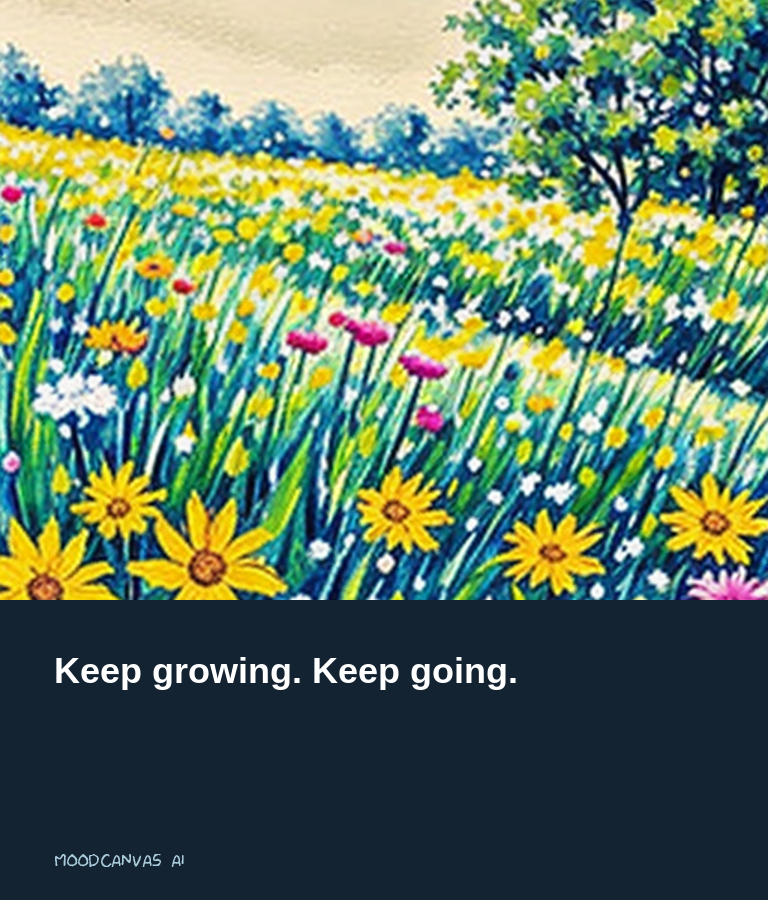

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
mood_text = 'I am very happy today.'  # Change this sentence.
assert mood_text.strip(), 'Please enter a sentence.'
start = time.perf_counter()
clean_text = ' '.join(mood_text.split())
prediction = emotion_model(clean_text, truncation=True, max_length=128)[0]
emotion = prediction['label']
quote, scene = designs[emotion]
prompt = f'Watercolor landscape, {scene}, beautiful scenery, no text, no letters'
result = image_model(prompt, num_inference_steps=4, guidance_scale=0.0,
    height=512, width=512, generator=torch.Generator('cuda').manual_seed(42))
flags = getattr(result, 'nsfw_content_detected', None)
if flags and any(flags):
    raise RuntimeError('The image safety check flagged this output. Try a different seed.')
poster = Image.new('RGB', (768, 900), '#142332')
poster.paste(ImageOps.fit(result.images[0], (768, 600)), (0, 0))
draw = ImageDraw.Draw(poster)

# Find an available Colab font instead of assuming one fixed file path.
from pathlib import Path
font_paths = list(Path('/usr/share/fonts').rglob('*.ttf'))
def poster_font(size, bold=False):
    preferred = [p for p in font_paths if ('sans' in p.name.lower()) and
                 (('bold' in p.name.lower()) == bold)]
    for path in preferred + font_paths:
        try:
            return ImageFont.truetype(str(path), size)
        except OSError:
            continue
    return ImageFont.load_default(size=size)

font = poster_font(36, bold=True)
lines, line = [], ''
for word in quote.split():
    candidate = (line + ' ' + word).strip()
    if draw.textlength(candidate, font=font) > 660 and line:
        lines.append(line)
        line = word
    else:
        line = candidate
lines.append(line)
for i, line in enumerate(lines):
    draw.text((54, 650 + i * 52), line, fill='white', font=font)
small_font = poster_font(18)
draw.text((54, 850), 'MOODCANVAS AI', fill='#A8CADA', font=small_font)
poster.save('/content/MoodCanvas_Poster.png')
generation_seconds = time.perf_counter() - start
print(f'Predicted emotion: {emotion}. Model score: {prediction["score"]:.1%}')
print('This score is not a guarantee that the prediction is correct.')
print(f'Poster creation time: {generation_seconds:.1f} seconds')
display(poster)
files.download('/content/MoodCanvas_Poster.png')

## 5. Small demonstration test
We use **14 original example sentences**, two for each emotion. They are manually labeled for this classroom demo and are not a standard benchmark or proof of general performance. We do not fit or tune models on them.

**Accuracy:** fraction of predictions matching our labels. **Macro-F1:** average F1 across all seven emotions. Image generation is checked by showing the actual poster and reporting its generation time. These metrics do not measure whether the poster improves someone's mood.


In [14]:
from sklearn.metrics import accuracy_score, f1_score
examples = [
    ('I am very sad and lonely today.', 'sadness'),
    ('I feel heartbroken after losing my friend.', 'sadness'),
    ('I am so happy about my wonderful results!', 'joy'),
    ('I feel delighted and cheerful today.', 'joy'),
    ('I am furious that you lied to me.', 'anger'),
    ('I am angry because someone broke my phone.', 'anger'),
    ('I am terrified of the dark.', 'fear'),
    ('I am scared about what might happen tomorrow.', 'fear'),
    ('Wow, I never expected this amazing gift!', 'surprise'),
    ('I am astonished by this unexpected news.', 'surprise'),
    ('That rotten food smells disgusting.', 'disgust'),
    ('I feel sick looking at that filthy rubbish.', 'disgust'),
    ('The meeting starts at three oclock.', 'neutral'),
    ('The book is on the table.', 'neutral')
]
answers = emotion_model([text for text, label in examples], truncation=True, max_length=128)
actual = [label for text, label in examples]
predicted = [answer['label'] for answer in answers]
accuracy = accuracy_score(actual, predicted)
macro_f1 = f1_score(actual, predicted, labels=list(designs), average='macro', zero_division=0)
for (text, label), guess in zip(examples, predicted):
    print(f'{label:9} | {guess:9} | {text}')
print(f'Classroom demo accuracy: {accuracy:.1%}; macro-F1: {macro_f1:.3f}')
summary = {'test_size': 14, 'accuracy': accuracy, 'macro_f1': macro_f1,
           'poster_emotion': globals().get('emotion'),
           'generation_seconds': globals().get('generation_seconds'),
           'note': 'Small manually labeled demonstration, not a benchmark.'}
with open('/content/MoodCanvas_Results.json', 'w') as f:
    json.dump(summary, f, indent=2)
files.download('/content/MoodCanvas_Results.json')

sadness   | sadness   | I am very sad and lonely today.
sadness   | sadness   | I feel heartbroken after losing my friend.
joy       | joy       | I am so happy about my wonderful results!
joy       | joy       | I feel delighted and cheerful today.
anger     | anger     | I am furious that you lied to me.
anger     | anger     | I am angry because someone broke my phone.
fear      | fear      | I am terrified of the dark.
fear      | fear      | I am scared about what might happen tomorrow.
surprise  | surprise  | Wow, I never expected this amazing gift!
surprise  | surprise  | I am astonished by this unexpected news.
disgust   | disgust   | That rotten food smells disgusting.
disgust   | disgust   | I feel sick looking at that filthy rubbish.
neutral   | neutral   | The meeting starts at three oclock.
neutral   | neutral   | The book is on the table.
Classroom demo accuracy: 100.0%; macro-F1: 1.000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>